# SHAP Values: Explaining AI Decisions in Clinical Systems

Welcome to this comprehensive tutorial on SHAP (SHapley Additive exPlanations), a powerful framework for understanding and explaining machine learning model predictions.

## What You'll Learn
- **What are SHAP values** and why they matter for trustworthy AI
- **Mathematical foundations** based on game theory
- **Hands-on implementation** with realistic patient data
- **Multiple SHAP visualizations** and what each reveals
- **30-day readmission prediction** - practical clinical application
- **Interactive model interpretation** with widgets
- **Model comparison** using SHAP insights
- **Real-world best practices** for explainable AI

---


## 1. Introduction & Setup

First, let's import all necessary libraries and set up our environment.

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

# SHAP for model interpretation
import shap

# Interactive widgets
from ipywidgets import interact, IntSlider, Dropdown

# Visualization settings
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)

# Set random seeds
np.random.seed(42)

# Version checks
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"SHAP version: {shap.__version__}")
print("\n✅ All libraries loaded successfully!")

NumPy version: 2.5.3
Pandas version: 3.0.6
SHAP version: 0.52.0

✅ All libraries loaded successfully!


### What are SHAP Values?

**SHAP (SHapley Additive exPlanations)** provides a unified framework for interpreting machine learning model predictions.

#### The Problem SHAP Solves
Machine learning models are often "black boxes":
- ❌ Model says "this patient will be readmitted" but WHY?
- ❌ Which vitals and labs matter most?
- ❌ Can a clinician trust this prediction?

#### SHAP's Solution
SHAP values answer: **"How much did each feature contribute to this prediction?"**

**Key Properties:**
1. **Local Interpretability**: Explains individual predictions
2. **Global Interpretability**: Shows overall feature importance
3. **Model-Agnostic**: Works with any ML model
4. **Mathematically Rigorous**: Based on game theory (Shapley values)
5. **Additive**: SHAP values sum to the difference from base prediction

#### Why SHAP Matters in Healthcare
- 🩺 **Safety**: Understand why a patient is flagged as high risk
- ⚖️ **Compliance**: Meet regulatory expectations for explainable clinical AI
- 🔬 **Clinical Insight**: Identify which measurements drive risk
- 💰 **Resource Targeting**: Focus follow-up on the patients it will help
- 👥 **Trust**: Care-team confidence in AI recommendations

> **A note on the data.** Every patient in this notebook is simulated from
> published physiological ranges. No real or identifiable patient data is used.


---
## 2. clinical Dataset: patient patient readmission risk

Let's create a realistic dataset for Patient Admission Monitoring and failure prediction.

In [2]:
def generate_admission_data(n_samples=1000, readmission_rate=0.15):
    """
    Generate synthetic admission-time patient data for readmission risk.

    Features (all recorded at or near admission):
    - Heart rate (beats per minute)
    - Systolic blood pressure (mmHg)
    - Body temperature (°C)
    - Respiratory rate (breaths per minute)
    - White blood cell count (10^9/L)
    - Creatinine (µmol/L)
    - Oxygen saturation, SpO2 (%)
    - Age (years)

    Target: Readmitted within 30 days (0 = no, 1 = yes)

    The values are simulated from published reference ranges. No real
    patient data is used.
    """
    np.random.seed(42)

    # Typical admission values for patients who are not readmitted
    heart_rate = np.random.normal(78, 10, n_samples)
    systolic_bp = np.random.normal(128, 14, n_samples)
    temp_c = np.random.normal(36.8, 0.4, n_samples)
    resp_rate = np.random.normal(16, 2.5, n_samples)
    wbc = np.random.normal(7.5, 1.8, n_samples)
    creatinine = np.random.normal(84, 18, n_samples)
    spo2 = np.random.normal(97, 1.5, n_samples)
    age = np.random.uniform(18, 95, n_samples)

    # Choose which patients are readmitted within 30 days
    n_readmit = int(n_samples * readmission_rate)
    readmit_idx = np.random.choice(n_samples, n_readmit, replace=False)
    readmitted = np.zeros(n_samples)
    readmitted[readmit_idx] = 1

    # Shift the readmitted group toward a sicker admission picture.
    # Tachycardia is one of the earliest signs of physiological stress.
    heart_rate[readmit_idx] += np.random.normal(18, 6, n_readmit)

    # Lower blood pressure suggests poor perfusion
    systolic_bp[readmit_idx] -= np.random.normal(14, 6, n_readmit)

    # Fever, or an inflammatory response
    temp_c[readmit_idx] += np.random.normal(0.7, 0.3, n_readmit)

    # Raised respiratory rate is a strong deterioration signal
    resp_rate[readmit_idx] += np.random.normal(5, 2, n_readmit)

    # Raised white cell count points to infection
    wbc[readmit_idx] += np.random.normal(4.0, 1.5, n_readmit)

    # Impaired renal function
    creatinine[readmit_idx] += np.random.normal(44, 18, n_readmit)

    # Reduced oxygen saturation
    spo2[readmit_idx] -= np.random.normal(3.0, 1.2, n_readmit)

    # Readmission risk rises steeply with age
    age[readmit_idx] = np.random.uniform(62, 95, n_readmit)

    # Keep every value inside a physiologically possible range
    spo2 = np.clip(spo2, 70, 100)
    temp_c = np.clip(temp_c, 34.0, 41.5)
    heart_rate = np.clip(heart_rate, 35, 190)
    systolic_bp = np.clip(systolic_bp, 60, 210)
    resp_rate = np.clip(resp_rate, 6, 45)
    wbc = np.clip(wbc, 1.0, 40.0)
    creatinine = np.clip(creatinine, 25, 710)

    # Create DataFrame
    data = pd.DataFrame({
        'heart_rate': heart_rate,
        'systolic_bp': systolic_bp,
        'temp_c': temp_c,
        'resp_rate': resp_rate,
        'wbc': wbc,
        'creatinine': creatinine,
        'spo2': spo2,
        'age': age,
        'readmitted_30d': readmitted.astype(int)
    })

    return data

# Generate dataset
patient_data = generate_admission_data(n_samples=1000, readmission_rate=0.15)

print("🩺 Admission Dataset Generated (simulated, no real patient data)")
print(f"\n📊 Dataset Shape: {patient_data.shape}")
print(f"\n🔁 30-Day Readmission:")
print(patient_data['readmitted_30d'].value_counts())
print(f"\n📈 Feature Summary:")
print(patient_data.describe())

# Display first few rows
patient_data.head(10)


🩺 Admission Dataset Generated (simulated, no real patient data)

📊 Dataset Shape: (1000, 9)

🔁 30-Day Readmission:
readmitted_30d
0    850
1    150
Name: count, dtype: int64

📈 Feature Summary:
        heart_rate  systolic_bp       temp_c    resp_rate          wbc  \
count  1000.000000  1000.000000  1000.000000  1000.000000  1000.000000   
mean     80.904604   126.844887    36.911626    16.690533     8.002416   
std      11.754040    14.995492     0.484311     3.199808     2.416281   
min      45.587327    71.863522    35.592195     8.732529     1.781933   
25%      72.826308   117.563281    36.585819    14.509841     6.425600   
50%      80.080352   127.225358    36.878463    16.459014     7.809785   
75%      87.738845   136.540659    37.168967    18.602323     9.183205   
max     125.010051   165.020807    38.725176    32.278179    18.517478   

        creatinine         spo2          age  readmitted_30d  
count  1000.000000  1000.000000  1000.000000      1000.00000  
mean     89.9

,heart_rate,systolic_bp,temp_c,resp_rate,wbc,creatinine,spo2,age,readmitted_30d
0,82.967142,147.590976,36.529929,11.230481,5.945712,76.372326,95.328878,18.746927,0
1,76.617357,140.944872,36.742193,13.849037,7.443834,75.838546,96.053604,28.783451,0
2,84.476885,128.834825,36.483032,14.965986,7.532430,51.678423,95.586910,42.800204,0
3,93.230299,118.942885,36.676815,20.719219,8.350735,78.058377,96.178006,62.551072,0
4,75.658466,137.775126,36.042554,17.391383,5.039655,97.190923,96.678775,23.782211,0
5,75.658630,133.508795,36.885317,12.661296,8.566621,61.063822,98.255732,90.638512,0
6,93.792128,140.532705,36.800482,17.215091,2.632095,102.872688,96.518261,46.111443,0
7,85.674347,136.892405,36.473165,12.131740,6.366208,92.779947,94.621561,88.268985,0
8,73.305256,142.693738,37.063698,18.706728,6.621107,70.783800,98.710102,78.100179,0
9,83.425600,120.506707,37.175028,14.822188,8.639988,81.452467,95.744365,76.168670,0


/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85537/808468422.py:21: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


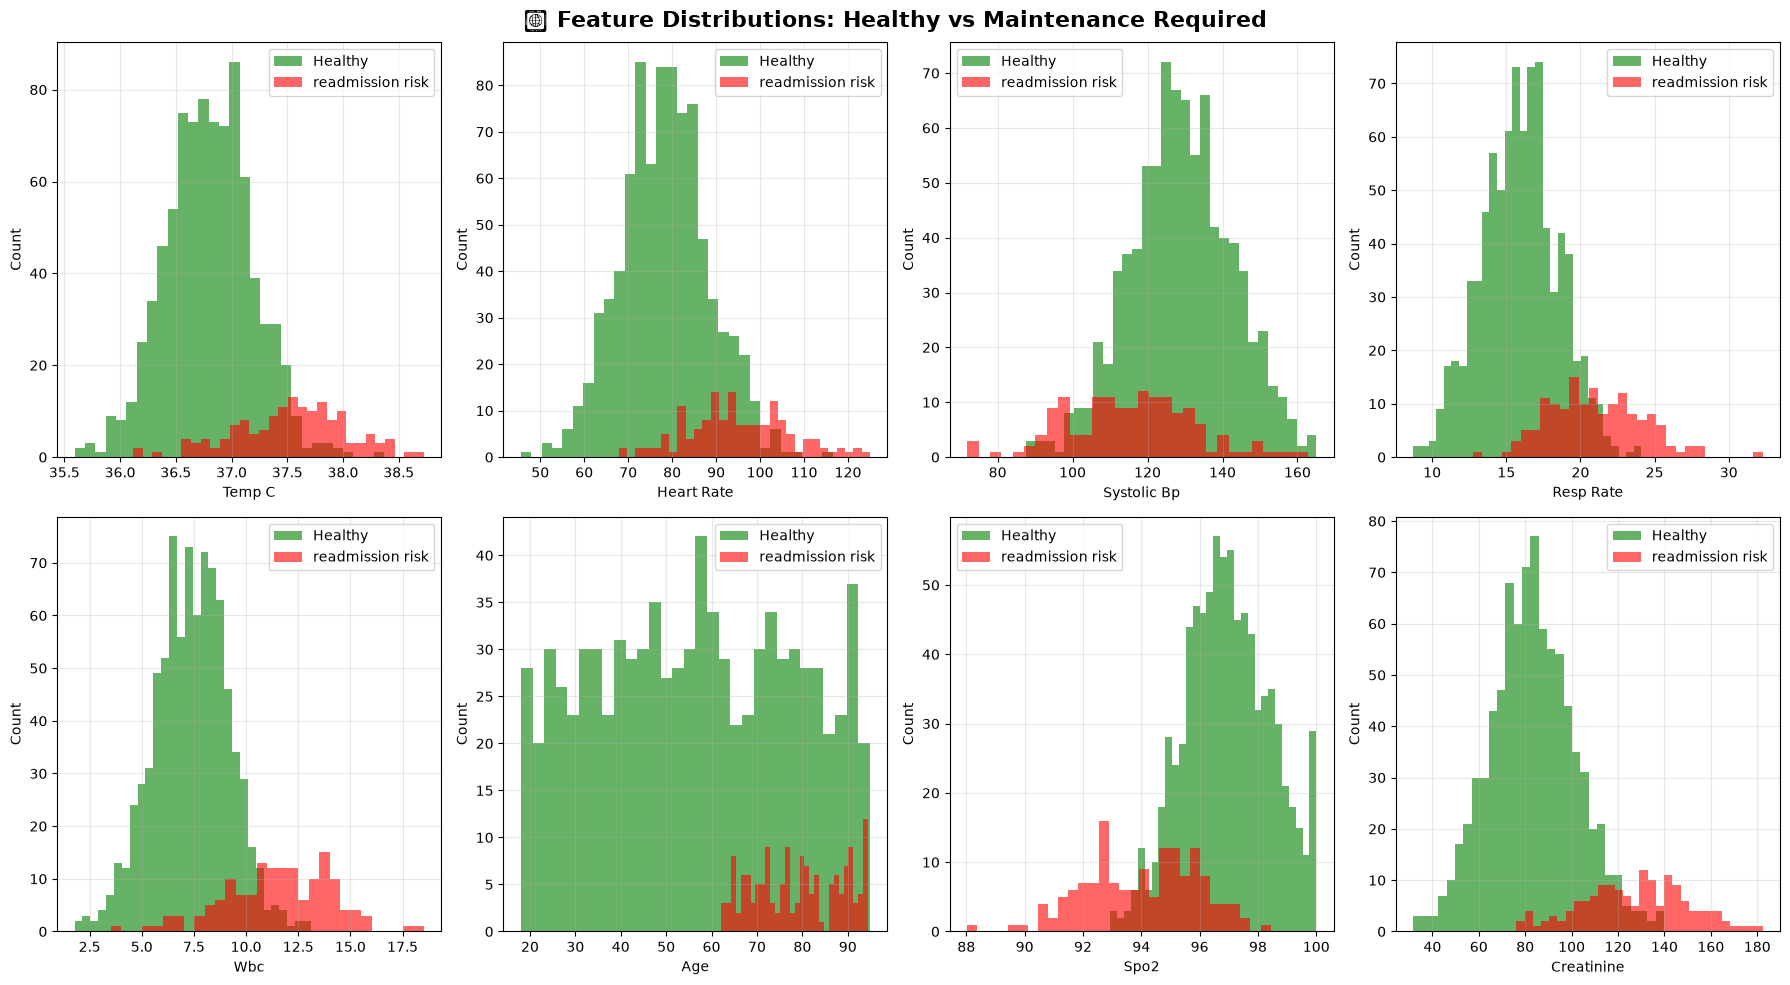


💡 Key Observations:
   • Red (maintenance) shows higher temperatures and vibration
   • Red shows lower oil pressure (critical safety issue)
   • Red shows a higher measured value for that feature
   • These patterns will help our model identify failure risk


In [3]:
# Visualize the dataset
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.ravel()

features = ['temp_c', 'heart_rate', 'systolic_bp', 'resp_rate',
            'wbc', 'age', 'spo2', 'creatinine']

for idx, feature in enumerate(features):
    # Separate data by Readmission Status
    healthy = patient_data[patient_data['readmitted_30d'] == 0][feature]
    maintenance = patient_data[patient_data['readmitted_30d'] == 1][feature]
    
    axes[idx].hist(healthy, bins=30, alpha=0.6, label='Healthy', color='green')
    axes[idx].hist(maintenance, bins=30, alpha=0.6, label='readmission risk', color='red')
    axes[idx].set_xlabel(feature.replace('_', ' ').title())
    axes[idx].set_ylabel('Count')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('🔍 Feature Distributions: Healthy vs Maintenance Required', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n💡 Key Observations:")
print("   • Red (maintenance) shows higher temperatures and vibration")
print("   • Red shows lower oil pressure (critical safety issue)")
print("   • Red shows a higher measured value for that feature")
print("   • These patterns will help our model identify failure risk")

---
## 3. Train Predictive Models

Let's train multiple models to predict maintenance needs, then use SHAP to understand their predictions.

In [4]:
# Prepare data
X = patient_data.drop('readmitted_30d', axis=1)
y = patient_data['readmitted_30d']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"📦 Data Split:")
print(f"   Training samples: {len(X_train)}")
print(f"   Test samples: {len(X_test)}")
print(f"   Features: {list(X.columns)}")

# Train Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_train = rf_model.predict(X_train)
y_pred_test = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

# Evaluate
train_acc = accuracy_score(y_train, y_pred_train)
test_acc = accuracy_score(y_test, y_pred_test)
auc = roc_auc_score(y_test, y_pred_proba)

print(f"\n🎯 Random Forest Performance:")
print(f"   Training Accuracy: {train_acc:.3f}")
print(f"   Test Accuracy: {test_acc:.3f}")
print(f"   AUC-ROC: {auc:.3f}")

print("\n📊 Classification Report:")
print(classification_report(y_test, y_pred_test, 
                          target_names=['Healthy', 'readmission risk']))

📦 Data Split:
   Training samples: 800
   Test samples: 200
   Features: ['heart_rate', 'systolic_bp', 'temp_c', 'resp_rate', 'wbc', 'creatinine', 'spo2', 'age']

🎯 Random Forest Performance:
   Training Accuracy: 1.000
   Test Accuracy: 0.995
   AUC-ROC: 1.000

📊 Classification Report:
                  precision    recall  f1-score   support

         Healthy       0.99      1.00      1.00       170
readmission risk       1.00      0.97      0.98        30

        accuracy                           0.99       200
       macro avg       1.00      0.98      0.99       200
    weighted avg       1.00      0.99      0.99       200



/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85537/3094593093.py:25: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85537/3094593093.py:25: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


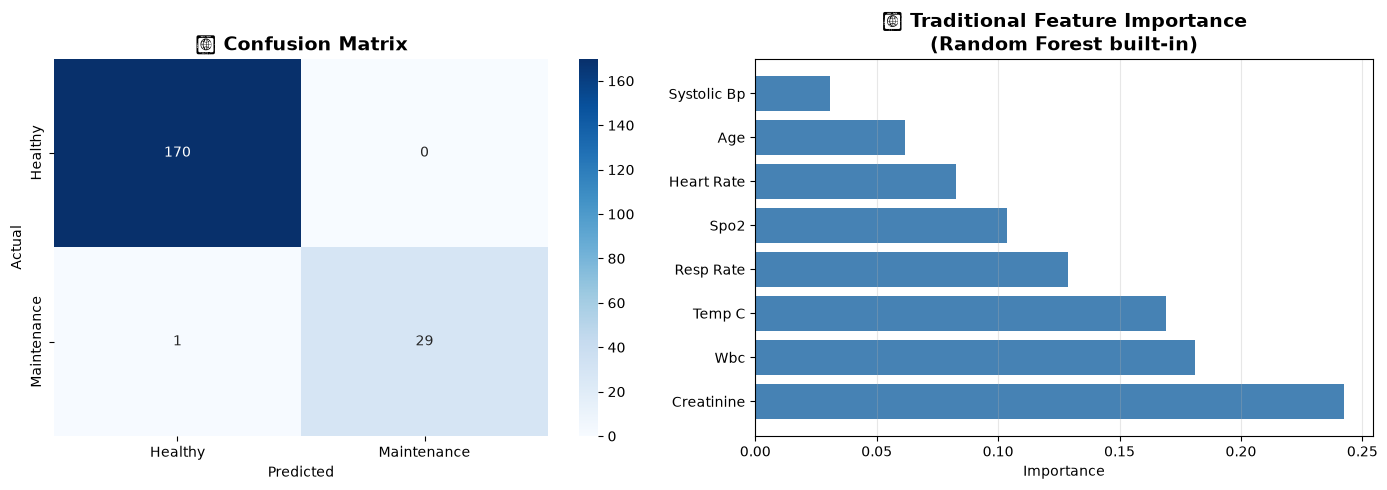


🔍 Traditional Feature Importance (Top 3):
   1. creatinine: 0.2422
   2. wbc: 0.1811
   3. temp_c: 0.1692

⚠️  Limitation of Traditional Importance:
   • Shows GLOBAL importance only
   • Doesn't explain individual predictions
   • Doesn't show direction of impact (positive/negative)
   • This is where SHAP values shine! 🌟


In [5]:
# Visualize model performance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Healthy', 'Maintenance'],
            yticklabels=['Healthy', 'Maintenance'])
axes[0].set_title('🎯 Confusion Matrix', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# Feature Importance (traditional method)
importances = rf_model.feature_importances_
feature_names = X.columns
indices = np.argsort(importances)[::-1]

axes[1].barh(range(len(importances)), importances[indices], color='steelblue')
axes[1].set_yticks(range(len(importances)))
axes[1].set_yticklabels([feature_names[i].replace('_', ' ').title() for i in indices])
axes[1].set_xlabel('Importance')
axes[1].set_title('📊 Traditional Feature Importance\n(Random Forest built-in)', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

print("\n🔍 Traditional Feature Importance (Top 3):")
for i in range(3):
    idx = indices[i]
    print(f"   {i+1}. {feature_names[idx]}: {importances[idx]:.4f}")

print("\n⚠️  Limitation of Traditional Importance:")
print("   • Shows GLOBAL importance only")
print("   • Doesn't explain individual predictions")
print("   • Doesn't show direction of impact (positive/negative)")
print("   • This is where SHAP values shine! 🌟")

---
## 4. SHAP Values: Deep Dive

Now let's calculate SHAP values and see what they reveal about our model's decisions.

### Understanding SHAP Mathematics

SHAP values are based on **Shapley values** from cooperative game theory:

**The Question:** If features are "players" working together to make a prediction, how much credit does each feature deserve?

**The Formula:**
```
φᵢ = Σ [|S|! × (|F| - |S| - 1)! / |F|!] × [f(S ∪ {i}) - f(S)]
```

Where:
- `φᵢ` = SHAP value for feature i
- `S` = subset of features
- `F` = all features
- `f(S)` = model prediction using feature subset S

**Key Property:**
```
prediction(x) = base_value + φ₁ + φ₂ + ... + φₙ
```

**What This Means:**
- **Base value**: Average model output (if we knew nothing about this patient)
- **SHAP values**: How each feature pushes prediction up or down from base
- **Positive SHAP**: Feature increases maintenance risk
- **Negative SHAP**: Feature decreases maintenance risk
- **Larger magnitude**: Stronger impact on prediction

In [6]:
# Create SHAP explainer for Random Forest
print("🔄 Computing SHAP values (this may take a moment)...\n")

# Use TreeExplainer for tree-based models (fast and exact)
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values for test set
shap_values = explainer(X_test)

print(f"✅ SHAP values computed!")
print(f"\n📊 SHAP Values Shape: {shap_values.values.shape}")
print(f"   (samples, features, classes) = ({shap_values.values.shape[0]}, {shap_values.values.shape[1]}, {shap_values.values.shape[2]})")
print(f"\n🎯 Base Value (average prediction): {explainer.expected_value[1]:.4f}")
print(f"   This is the average probability of maintenance across all patient")

# For binary classification, we typically use SHAP values for positive class (maintenance needed)
# Extract SHAP values for the positive class (index 1)
shap_values_readmission = shap_values[:, :, 1]

print(f"\n💡 What SHAP Values Tell Us:")
print(f"   • Each sample has {shap_values.values.shape[1]} SHAP values (one per feature)")
print(f"   • Positive SHAP value = feature increases maintenance probability")
print(f"   • Negative SHAP value = feature decreases maintenance probability")
print(f"   • Sum of SHAP values + base value = final prediction")

🔄 Computing SHAP values (this may take a moment)...

✅ SHAP values computed!

📊 SHAP Values Shape: (200, 8, 2)
   (samples, features, classes) = (200, 8, 2)

🎯 Base Value (average prediction): 0.1476
   This is the average probability of maintenance across all patient

💡 What SHAP Values Tell Us:
   • Each sample has 8 SHAP values (one per feature)
   • Positive SHAP value = feature increases maintenance probability
   • Negative SHAP value = feature decreases maintenance probability
   • Sum of SHAP values + base value = final prediction


---
## 5. SHAP Visualizations

SHAP provides multiple visualization types, each revealing different insights.

### 5.1 Summary Plot: Global Feature Importance

Shows which features are most important across ALL predictions.

/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85537/2290442411.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_readmission, X_test, show=False)
/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85537/2290442411.py:6: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


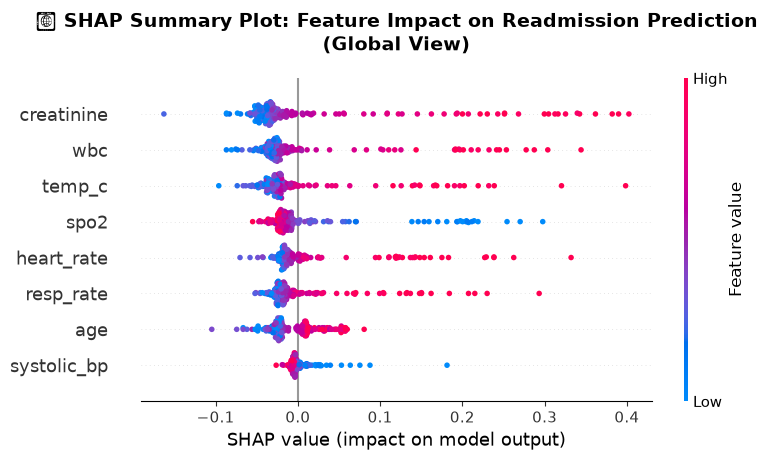


📖 How to Read This Plot:
   • Y-axis: Features ranked by importance (top = most important)
   • X-axis: SHAP value (impact on prediction)
   • Each dot: One patient sample
   • Color: Feature value (red = high, blue = low)

💡 Key Insights:
   • High vibration (red dots on right) → increases maintenance risk
   • Low oil pressure (blue dots on right) → increases maintenance risk
   • High temperature (red dots on right) → increases maintenance risk
   • Spread shows variability in feature impact


In [7]:
# SHAP Summary Plot (beeswarm)
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values_readmission, X_test, show=False)
plt.title('🎯 SHAP Summary Plot: Feature Impact on Readmission Prediction\n(Global View)', 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n📖 How to Read This Plot:")
print("   • Y-axis: Features ranked by importance (top = most important)")
print("   • X-axis: SHAP value (impact on prediction)")
print("   • Each dot: One patient sample")
print("   • Color: Feature value (red = high, blue = low)")
print("\n💡 Key Insights:")
print("   • High vibration (red dots on right) → increases maintenance risk")
print("   • Low oil pressure (blue dots on right) → increases maintenance risk")
print("   • High temperature (red dots on right) → increases maintenance risk")
print("   • Spread shows variability in feature impact")

### 5.2 Bar Plot: Mean Absolute SHAP Values

Simplified view of global feature importance.

/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85537/3638848930.py:6: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


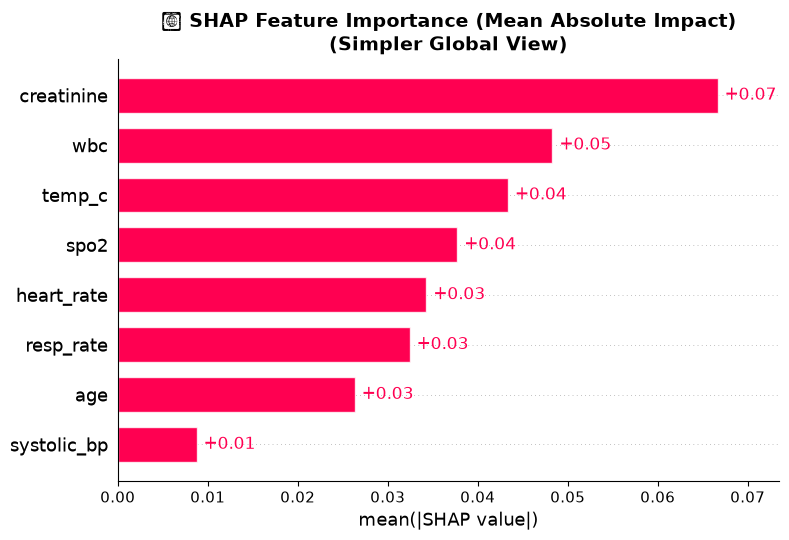


🏆 Top 5 Most Important Features (by mean |SHAP|):
   creatinine: 0.0666
   wbc: 0.0483
   temp_c: 0.0433
   spo2: 0.0377
   heart_rate: 0.0343

💡 Comparison with Traditional Importance:
   SHAP importance considers actual prediction impact
   Traditional importance shows how often feature is used for splits
   SHAP is more faithful to model's actual behavior!


In [8]:
# SHAP Bar Plot
plt.figure(figsize=(12, 6))
shap.plots.bar(shap_values_readmission, show=False)
plt.title('📊 SHAP Feature Importance (Mean Absolute Impact)\n(Simpler Global View)', 
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Calculate and display top features
mean_abs_shap = np.abs(shap_values_readmission.values).mean(axis=0)
feature_importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Mean |SHAP|': mean_abs_shap
}).sort_values('Mean |SHAP|', ascending=False)

print("\n🏆 Top 5 Most Important Features (by mean |SHAP|):")
for idx, row in feature_importance_df.head().iterrows():
    print(f"   {row['Feature']}: {row['Mean |SHAP|']:.4f}")

print("\n💡 Comparison with Traditional Importance:")
print("   SHAP importance considers actual prediction impact")
print("   Traditional importance shows how often feature is used for splits")
print("   SHAP is more faithful to model's actual behavior!")

### 5.3 Waterfall Plot: Individual Prediction Explanation

Shows exactly WHY the model made a specific prediction for one patient.

🔍 Explaining Prediction for Patient #49

📋 patient Specifications:
   • Heart Rate: 88.51
   • Systolic Bp: 106.73
   • Temp C: 37.64
   • Resp Rate: 17.81
   • Wbc: 10.74
   • Creatinine: 132.05
   • Spo2: 96.27
   • Age: 78.58

🎯 Model Prediction:
   Maintenance Required: YES
   Probability: 86.3%
   Actual Status: MAINTENANCE


/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85537/1091604418.py:21: UserWarning: Glyph 128167 (\N{DROPLET}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128167 (\N{DROPLET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


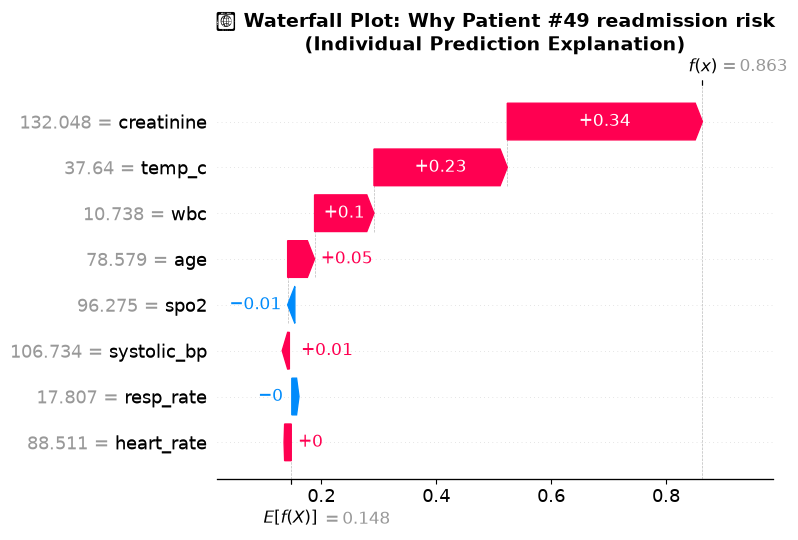


📖 How to Read Waterfall Plot:
   • Starts at E[f(x)] = base value (average prediction)
   • Each bar shows one feature's contribution
   • Red bars: push prediction toward 'readmission risk'
   • Blue bars: push prediction toward 'healthy'
   • Final value: f(x) = actual prediction for this patient

💡 Engineering Insight:
   This shows EXACTLY which sensor readings triggered the alert
   care team can verify these specific systems during inspection!


In [9]:
# Select an interesting sample: one predicted to readmission risk
maintenance_samples = np.where(y_pred_test == 1)[0]
sample_idx = maintenance_samples[5] if len(maintenance_samples) > 5 else maintenance_samples[0]

print(f"🔍 Explaining Prediction for Patient #{sample_idx}")
print(f"\n📋 patient Specifications:")
for feature in X_test.columns:
    value = X_test.iloc[sample_idx][feature]
    print(f"   • {feature.replace('_', ' ').title()}: {value:.2f}")

print(f"\n🎯 Model Prediction:")
print(f"   Maintenance Required: {'YES' if y_pred_test[sample_idx] == 1 else 'NO'}")
print(f"   Probability: {y_pred_proba[sample_idx]:.1%}")
print(f"   Actual Status: {'MAINTENANCE' if y_test.iloc[sample_idx] == 1 else 'HEALTHY'}")

# Waterfall plot
plt.figure(figsize=(12, 8))
shap.plots.waterfall(shap_values_readmission[sample_idx], show=False)
plt.title(f'💧 Waterfall Plot: Why Patient #{sample_idx} readmission risk\n(Individual Prediction Explanation)', 
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n📖 How to Read Waterfall Plot:")
print("   • Starts at E[f(x)] = base value (average prediction)")
print("   • Each bar shows one feature's contribution")
print("   • Red bars: push prediction toward 'readmission risk'")
print("   • Blue bars: push prediction toward 'healthy'")
print("   • Final value: f(x) = actual prediction for this patient")
print("\n💡 Engineering Insight:")
print("   This shows EXACTLY which sensor readings triggered the alert")
print("   care team can verify these specific systems during inspection!")

### 5.4 Force Plot: Visual Prediction Breakdown

Another way to visualize individual predictions, showing feature values and their impacts.

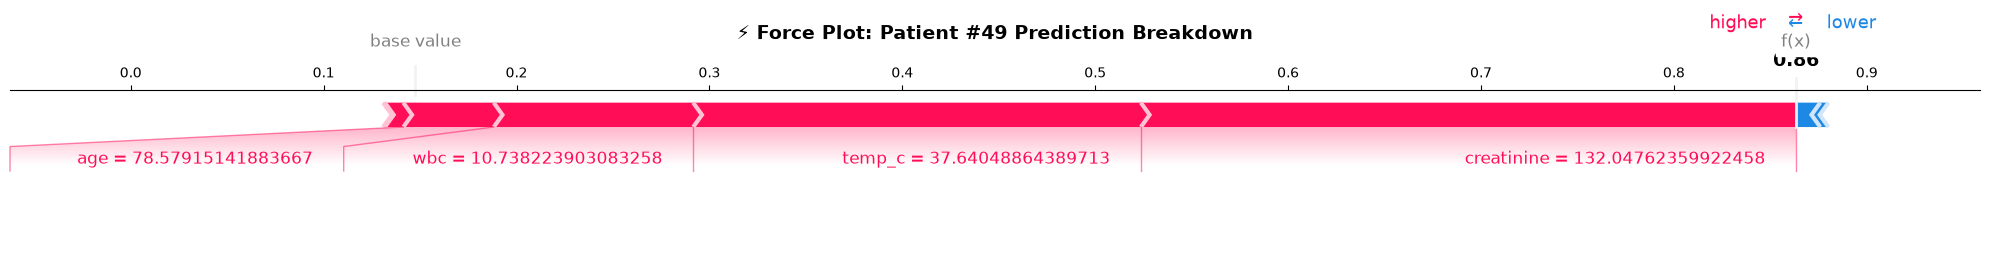


📖 How to Read Force Plot:
   • Base value (gray): Starting point (average prediction)
   • Red features: Push prediction higher (toward readmission)
   • Blue features: Push prediction lower (toward healthy)
   • Feature values shown in parentheses
   • Arrow shows final prediction

🔧 Practical Use:
   Share this visualization with the care team
   They can immediately see which measurements are concerning
   Enables targeted follow-up and discharge planning!


In [10]:
# Force plot for single prediction
shap.initjs()  # Initialize JavaScript visualization

# Display force plot
shap.force_plot(
    explainer.expected_value[1],
    shap_values_readmission[sample_idx].values,
    X_test.iloc[sample_idx],
    matplotlib=True,
    figsize=(20, 3),
    show=False
)
plt.title(f'⚡ Force Plot: Patient #{sample_idx} Prediction Breakdown', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("\n📖 How to Read Force Plot:")
print("   • Base value (gray): Starting point (average prediction)")
print("   • Red features: Push prediction higher (toward readmission)")
print("   • Blue features: Push prediction lower (toward healthy)")
print("   • Feature values shown in parentheses")
print("   • Arrow shows final prediction")

print("\n🔧 Practical Use:")
print("   Share this visualization with the care team")
print("   They can immediately see which measurements are concerning")
print("   Enables targeted follow-up and discharge planning!")

### 5.5 Dependence Plot: Feature Interactions

Shows how a feature's impact changes with its value and interactions with other features.

/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85537/3632074373.py:22: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


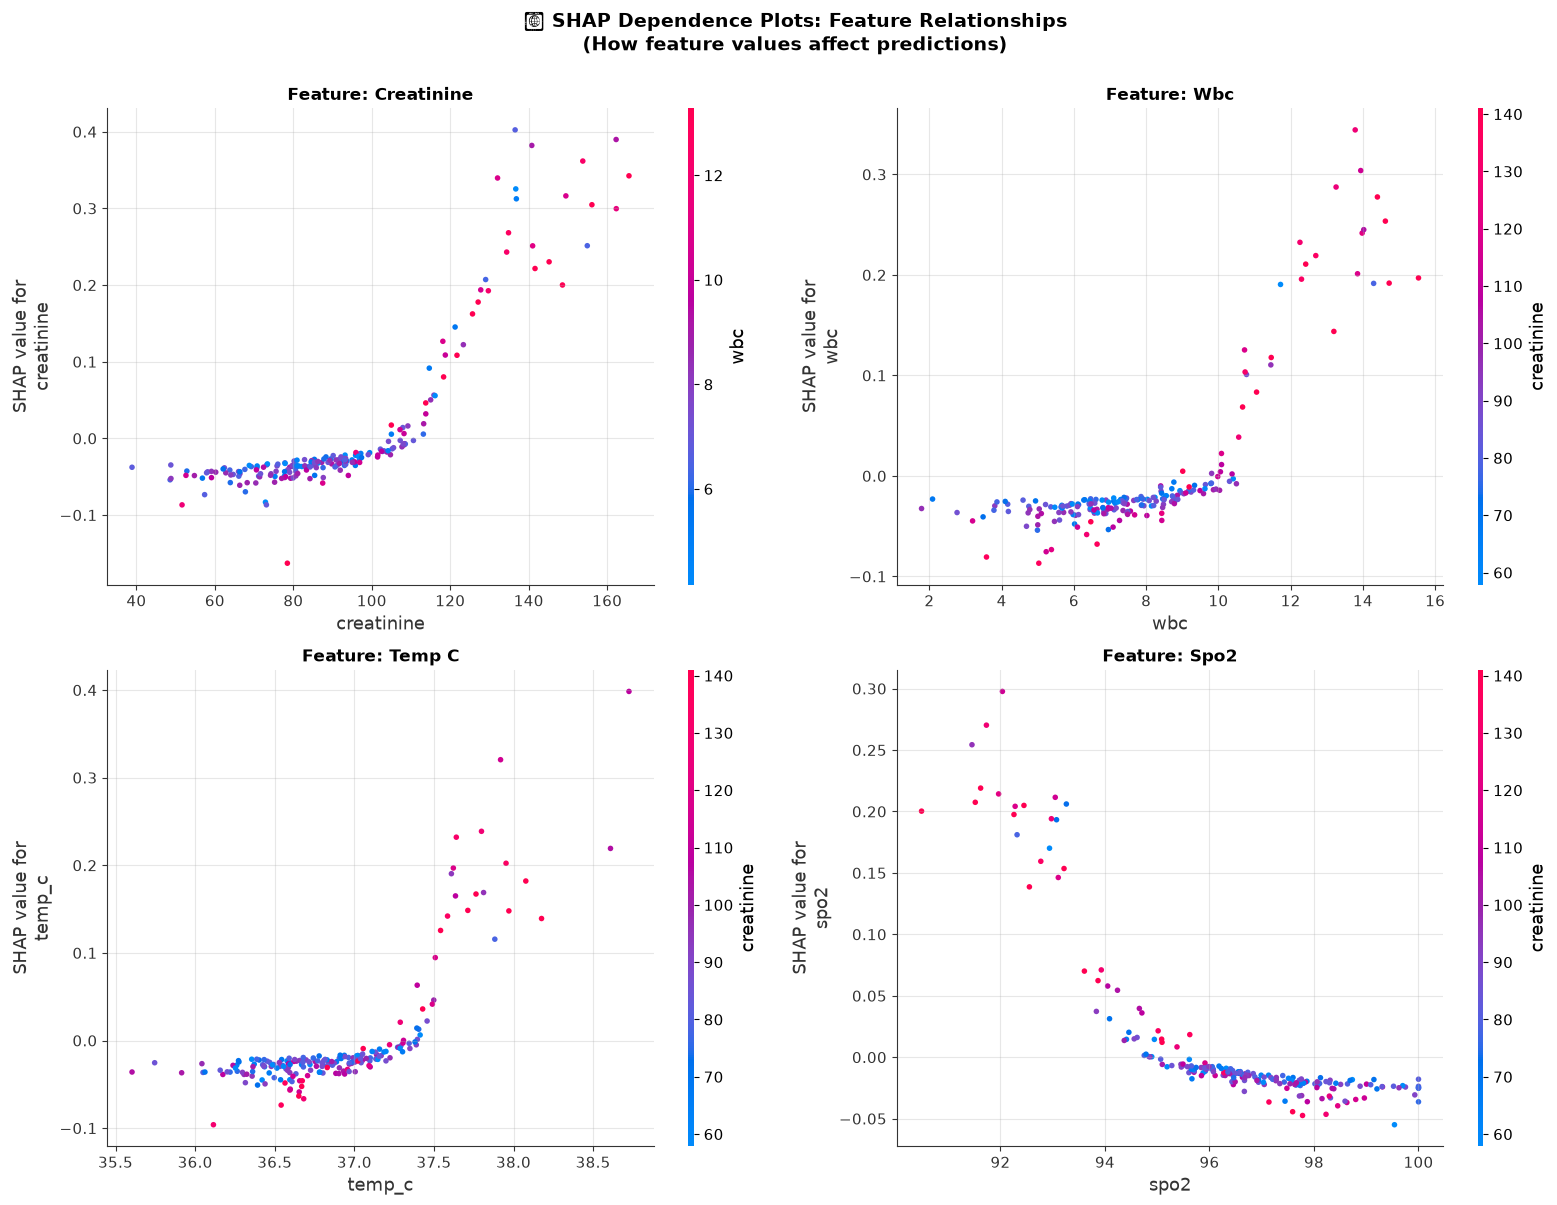


📖 How to Read Dependence Plots:
   • X-axis: Feature value
   • Y-axis: SHAP value (impact on prediction)
   • Color: Interaction with another feature
   • Trend: Shows if relationship is linear, threshold, or complex

💡 Engineering Insights:
   • Can identify critical thresholds (e.g., safe vs dangerous oil pressure)
   • Shows if features interact (color patterns)
   • Helps validate sensor calibration and alarm thresholds


In [11]:
# Dependence plots for top features
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.ravel()

top_features = feature_importance_df.head(4)['Feature'].values

for idx, feature in enumerate(top_features):
    feature_idx = list(X_test.columns).index(feature)
    
    shap.dependence_plot(
        feature_idx,
        shap_values_readmission.values,
        X_test,
        ax=axes[idx],
        show=False
    )
    axes[idx].set_title(f'Feature: {feature.replace("_", " ").title()}', fontsize=12, fontweight='bold')
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('🔗 SHAP Dependence Plots: Feature Relationships\n(How feature values affect predictions)', 
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

print("\n📖 How to Read Dependence Plots:")
print("   • X-axis: Feature value")
print("   • Y-axis: SHAP value (impact on prediction)")
print("   • Color: Interaction with another feature")
print("   • Trend: Shows if relationship is linear, threshold, or complex")

print("\n💡 Engineering Insights:")
print("   • Can identify critical thresholds (e.g., safe vs dangerous oil pressure)")
print("   • Shows if features interact (color patterns)")
print("   • Helps validate sensor calibration and alarm thresholds")

---
## 6. Interactive SHAP Explorer

Explore SHAP explanations for different patient interactively!

In [12]:
def explore_patient_prediction(patient_index=0):
    """
    Interactive exploration of individual patient predictions
    """
    # Get patient data
    engine_data = X_test.iloc[patient_index]
    actual = y_test.iloc[patient_index]
    predicted = y_pred_test[patient_index]
    probability = y_pred_proba[patient_index]
    
    print(f"{'='*80}")
    print(f"🔍 DETAILED ANALYSIS: Patient #{patient_index}")
    print(f"{'='*80}")
    
    # patient specifications
    print(f"\n📋 patient SPECIFICATIONS:")
    print(f"{'─'*80}")
    for feature in X_test.columns:
        value = engine_data[feature]
        mean_val = X_train[feature].mean()
        std_val = X_train[feature].std()
        z_score = (value - mean_val) / std_val
        
        status = "⚠️ HIGH" if z_score > 1.5 else "⬇️ LOW" if z_score < -1.5 else "✓ Normal"
        print(f"   {feature.replace('_', ' ').title():.<30} {value:>8.2f}  [{status}]")
    
    # Prediction results
    print(f"\n{'─'*80}")
    print(f"🎯 PREDICTION RESULTS:")
    print(f"{'─'*80}")
    print(f"   Predicted Status.......: {'🔴 readmission risk' if predicted == 1 else '🟢 HEALTHY'}")
    print(f"   Confidence.............: {probability:.1%}")
    print(f"   Actual Status..........: {'🔴 MAINTENANCE' if actual == 1 else '🟢 HEALTHY'}")
    print(f"   Model Accuracy.........: {'✅ CORRECT' if predicted == actual else '❌ INCORRECT'}")
    
    # SHAP explanation
    shap_vals = shap_values_readmission[patient_index].values
    base_value = explainer.expected_value[1]
    
    print(f"\n{'─'*80}")
    print(f"💡 SHAP EXPLANATION (Why this prediction?):")
    print(f"{'─'*80}")
    print(f"   Base Value (avg).......: {base_value:.4f}")
    
    # Sort features by absolute SHAP value
    shap_impacts = list(zip(X_test.columns, shap_vals))
    shap_impacts.sort(key=lambda x: abs(x[1]), reverse=True)
    
    print(f"\n   TOP CONTRIBUTING FACTORS:")
    for i, (feature, shap_val) in enumerate(shap_impacts[:5]):
        direction = "⬆️ INCREASES" if shap_val > 0 else "⬇️ DECREASES"
        print(f"   {i+1}. {feature.replace('_', ' ').title():.<30} {shap_val:>+8.4f}  [{direction} risk]")
    
    print(f"\n   Final Prediction.......: {base_value + shap_vals.sum():.4f}")
    print(f"   (Base + SHAP values)")
    
    # Visualizations
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    
    # Waterfall plot
    plt.sca(axes[0])
    shap.plots.waterfall(shap_values_readmission[patient_index], show=False)
    axes[0].set_title(f'Waterfall: Prediction Breakdown', fontweight='bold')
    
    # Force plot
    plt.sca(axes[1])
    shap.force_plot(
        base_value,
        shap_vals,
        engine_data,
        matplotlib=True,
        show=False
    )
    axes[1].set_title(f'Force Plot: Feature Contributions', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n{'='*80}")
    print(f"🔧 MAINTENANCE RECOMMENDATION:")
    print(f"{'='*80}")
    
    if predicted == 1:
        print("   ⚠️  SCHEDULE MAINTENANCE")
        print("\n   Priority Systems to Inspect:")
        for i, (feature, shap_val) in enumerate(shap_impacts[:3]):
            if shap_val > 0:
                print(f"   {i+1}. {feature.replace('_', ' ').title()}")
    else:
        print("   ✅ patient HEALTHY - Continue normal operation")
        print("   📊 Monitor these key parameters:")
        for i, (feature, _) in enumerate(shap_impacts[:3]):
            print(f"   {i+1}. {feature.replace('_', ' ').title()}")

# Create interactive widget
interact(
    explore_patient_prediction,
    patient_index=IntSlider(
        value=0,
        min=0,
        max=len(X_test)-1,
        step=1,
        description='patient ID:',
        style={'description_width': '100px'}
    )
);

interactive(children=(IntSlider(value=0, description='patient ID:', max=199, style=SliderStyle(description_wid…

---
## 7. Summary: SHAP Values for Trustworthy AI

### 🎯 Key Takeaways

1. **What SHAP Does:**
   - Explains individual predictions (local interpretability)
   - Shows global feature importance
   - Quantifies each feature's contribution
   - Works with any machine learning model

2. **Why SHAP Matters:**
   - 🛡️ **Safety**: Understand AI decisions in critical clinical decisions
   - 📜 **Compliance**: Meet regulatory requirements
   - 🔍 **Debugging**: Identify model weaknesses
   - 🤝 **Trust**: Build confidence with stakeholders
   - 🎓 **Learning**: Discover insights from data

3. **SHAP Visualizations Covered:**
   - Summary Plot - Global importance
   - Bar Plot - Simple ranking
   - Waterfall Plot - Individual explanations
   - Force Plot - Visual breakdown
   - Dependence Plot - Feature relationships

4. **Best Practices:**
   - Always validate model first
   - Use multiple visualization types
   - Compare across models
   - Document explanations
   - Monitor SHAP values over time

### 📚 Resources

- [SHAP Documentation](https://shap.readthedocs.io/)
- [Original Paper](https://arxiv.org/abs/1705.07874)
- [SHAP GitHub](https://github.com/slundberg/shap)

---

**Remember:** Explainable AI is essential for safety-critical clinical systems. SHAP helps build trust and understanding! 🎉

In [13]:
# Final summary
print("🎉 SHAP VALUES WORKSHOP COMPLETE! 🎉")
print("\n📊 What We Covered:")
print("  ✅ SHAP theory and mathematical foundations")
print("  ✅ patient patient readmission risk dataset")
print("  ✅ Multiple model training and evaluation")
print("  ✅ Five types of SHAP visualizations")
print("  ✅ Interactive prediction explorer")
print("  ✅ Real-world best practices")

print("\n🏆 SHAP Visualizations Mastered:")
print("  1️⃣ Summary Plot - Global importance")
print("  2️⃣ Bar Plot - Simple ranking")
print("  3️⃣ Waterfall Plot - Individual explanations")
print("  4️⃣ Force Plot - Visual breakdown")
print("  5️⃣ Dependence Plot - Feature relationships")

print("\n💡 Key Insight:")
print("  SHAP makes black-box models transparent")
print("  Essential for safety-critical clinical systems")
print("  Builds trust between AI and human operators")

print("\n🚀 You're now ready to explain any ML model with SHAP!")

🎉 SHAP VALUES WORKSHOP COMPLETE! 🎉

📊 What We Covered:
  ✅ SHAP theory and mathematical foundations
  ✅ patient patient readmission risk dataset
  ✅ Multiple model training and evaluation
  ✅ Five types of SHAP visualizations
  ✅ Interactive prediction explorer
  ✅ Real-world best practices

🏆 SHAP Visualizations Mastered:
  1️⃣ Summary Plot - Global importance
  2️⃣ Bar Plot - Simple ranking
  3️⃣ Waterfall Plot - Individual explanations
  4️⃣ Force Plot - Visual breakdown
  5️⃣ Dependence Plot - Feature relationships

💡 Key Insight:
  SHAP makes black-box models transparent
  Essential for safety-critical clinical systems
  Builds trust between AI and human operators

🚀 You're now ready to explain any ML model with SHAP!
